# Enterprise Multi-Modal Data Visualization and Storytelling
## Sample Superstore — Sales vs. Profitability

**Final project — Database Knowledge Extraction**  
**Team:** [Member 1], [Member 2], [Member 3], [Member 4], [Member 5]  
**Presentation:** November 24, 2026

**Business question:** Why do some high-revenue categories and regions generate poor profits?

This notebook documents acquisition, quality checks, transformations, descriptive statistics, confidence intervals, static charts and interactive charts. Source is an **educational retail sample**, not audited financial data from a real organization. The dataset records *order lines*, so `order_id` must be deduplicated to count orders.

**Reproducibility:** Run cells in order from the repository root. Files are written to `data/processed` and `outputs`.

### 1. Libraries and source data
The file is downloaded once from a public source. No fabricated records are added. Python 3.10+ is required, together with the packages in `requirements.txt`.

In [1]:
from pathlib import Path
from urllib.request import Request, urlopen
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from IPython.display import display

ROOT = Path.cwd()
RAW = ROOT / "data/raw/Sample_Superstore.csv"
PROCESSED = ROOT / "data/processed/superstore_clean.csv"
FIG_DIR = ROOT / "outputs/figures"
TABLE_DIR = ROOT / "outputs/tables"
for p in [RAW.parent, PROCESSED.parent, FIG_DIR, TABLE_DIR]: p.mkdir(parents=True, exist_ok=True)

SOURCE = "https://raw.githubusercontent.com/mikemooreviz/superstore/master/superstore.csv"
if not RAW.exists():
    req = Request(SOURCE, headers={"User-Agent":"Mozilla/5.0 (educational project)"})
    with urlopen(req, timeout=45) as response:
        payload = response.read()
    if not payload.startswith((b"\xef\xbb\xbfRow ID,", b"Row ID,")):
        raise ValueError("CSV source returned an unexpected header")
    RAW.write_bytes(payload)
print("Raw dataset:", RAW)

sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams.update({"figure.dpi":120, "savefig.dpi":220})

Raw dataset: /home/marco/projects/database-knowledge-extraction/data/raw/Sample_Superstore.csv


### 2. Quality inspection and cleaning
Postal codes are treated as **categorical identifiers**, never averaged. A missing postal code is preserved as missing (`Unknown` label only for display), because inventing one would corrupt the geographic data. We remove only fully duplicated rows, flag missing critical measures, and parse dates explicitly.

In [2]:
raw = pd.read_csv(RAW, encoding="utf-8-sig", dtype={"Postal Code":"string"})
print(f"Raw shape: {raw.shape[0]:,} rows × {raw.shape[1]} columns")
print("Missing values before cleaning:")
display(raw.isna().sum().loc[lambda x:x>0].to_frame("missing"))
print("Duplicated full rows:", raw.duplicated().sum())

df = raw.copy().drop_duplicates()
df.columns = [re.sub(r"[^a-z0-9]+", "_", str(c).strip().lower()).strip("_") for c in df.columns]
for col in ["order_date", "ship_date"]:
    df[col] = pd.to_datetime(df[col], format="%Y-%m-%d", errors="coerce")
for col in ["sales", "profit", "quantity", "discount"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")
for col in ["region", "category", "sub_category", "state", "segment", "city"]:
    df[col] = df[col].astype("string").str.strip()
critical = ["order_id", "order_date", "sales", "profit", "discount", "region", "category", "state"]
assert not df[critical].isna().any().any(), "Critical missing data; inspect before proceeding"
assert df["row_id"].is_unique, "Order-line row IDs should be unique"
assert df["discount"].between(0,1).all()
assert (df["sales"] > 0).all()
assert (df["ship_date"] >= df["order_date"]).all()

df["year"] = df["order_date"].dt.year
df["month"] = df["order_date"].dt.to_period("M").astype(str)
df["shipping_days"] = (df["ship_date"]-df["order_date"]).dt.days
df["profit_margin"] = df["profit"] / df["sales"]  # per line; for groups use SUM(profit)/SUM(sales)
df["postal_code_missing"] = df["postal_code"].isna()
df["postal_code"] = df["postal_code"].fillna("Unknown")
df["discount_band"] = pd.cut(
    df["discount"], bins=[-1e-9,0,0.2,0.4,1],
    labels=["0%", ">0–20%", ">20–40%", ">40%"], include_lowest=True
)
df.to_csv(PROCESSED,index=False)
print("Clean shape:", df.shape, "| years:",df.year.min(),"-",df.year.max())
print("Missing postal codes:", int(df.postal_code_missing.sum()))
display(df.head(3))

Raw shape: 9,994 rows × 21 columns
Missing values before cleaning:


,missing
Postal Code,11


Duplicated full rows: 0
Clean shape: (9994, 27) | years: 2015 - 2018
Missing postal codes: 11


,row_id,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,country,city,...,sales,quantity,discount,profit,year,month,shipping_days,profit_margin,postal_code_missing,discount_band
0,1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,261.96,2,0.0,41.9136,2017,2017-11,3,0.16,False,0%
1,2,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,731.94,3,0.0,219.5820,2017,2017-11,3,0.30,False,0%
2,3,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,14.62,2,0.0,6.8714,2017,2017-06,4,0.47,False,0%


### 3. Executive KPIs and grouped business statistics
Sales and profit are sums of order lines. Profit margin is calculated as `SUM(profit)/SUM(sales)`, **not** as the average of line-level margins. An order can contain multiple rows.

In [3]:
total_sales = float(df.sales.sum())
total_profit = float(df.profit.sum())
orders = df.order_id.nunique()
customers = df.customer_id.nunique()
print(f"Order lines: {len(df):,} | Unique orders: {orders:,} | Customers: {customers:,}")
print(f"Revenue: ${total_sales:,.2f} | Profit: ${total_profit:,.2f} | Margin: {total_profit/total_sales:.2%}")
print(f"Loss-making lines: {(df.profit<0).sum():,}")

def grouped(groupby):
    output = df.groupby(groupby, observed=True, dropna=False).agg(
        sales=("sales","sum"), profit=("profit","sum"),
        order_lines=("row_id","count"), orders=("order_id","nunique")
    ).reset_index()
    output["margin_pct"] = 100 * output.profit / output.sales
    return output

by_year = grouped("year")
by_category = grouped("category")
by_region = grouped("region")
by_state = grouped("state")
by_discount = grouped("discount_band")
by_month = grouped("month")
by_subcategory = grouped("sub_category")
for name, table in [("years",by_year),("categories",by_category),("regions",by_region),
                    ("states",by_state),("discount_bands",by_discount),("months",by_month),
                    ("subcategories",by_subcategory)]:
    table.to_csv(TABLE_DIR/f"{name}.csv",index=False)
display(by_category.round(2))
display(by_discount.round(2))

Order lines: 9,994 | Unique orders: 5,009 | Customers: 793
Revenue: $2,297,200.86 | Profit: $286,397.02 | Margin: 12.47%
Loss-making lines: 1,871


,category,sales,profit,order_lines,orders,margin_pct
0,Furniture,741999.80,18451.27,2121,1764,2.49
1,Office Supplies,719047.03,122490.80,6026,3742,17.04
2,Technology,836154.03,145454.95,1847,1544,17.40


,discount_band,sales,profit,order_lines,orders,margin_pct
0,0%,1087908.47,320987.60,4798,2644,29.51
1,>0–20%,846522.24,100785.47,3803,2507,11.91
2,>20–40%,234137.90,-35817.47,460,400,-15.30
3,>40%,128632.25,-99558.59,933,737,-77.40


### 4. Distribution of sales (histogram)
Retail line-item sales are right-skewed, so a logarithmic X axis makes the central mass visible without changing the underlying records.

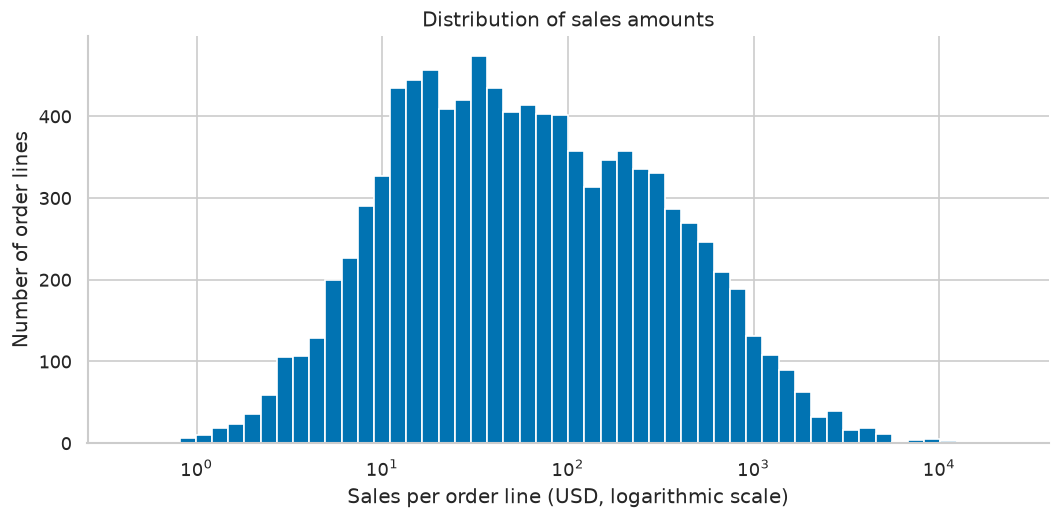

In [4]:
fig,ax=plt.subplots(figsize=(9,4.5))
ax.hist(df.sales,bins=np.logspace(np.log10(df.sales.min()),np.log10(df.sales.max()),55),edgecolor="white")
ax.set_xscale("log")
ax.set(xlabel="Sales per order line (USD, logarithmic scale)",ylabel="Number of order lines",title="Distribution of sales amounts")
sns.despine();fig.tight_layout()
fig.savefig(FIG_DIR/"01_sales_histogram.png")
fig.savefig(FIG_DIR/"01_sales_histogram.svg")
plt.show()

### 5. Profit distribution (KDE)
The display is restricted to the 1st–99th percentiles **only for visualization**; aggregates and conclusions continue using the complete data. The plot is descriptive and does not constitute causal evidence.

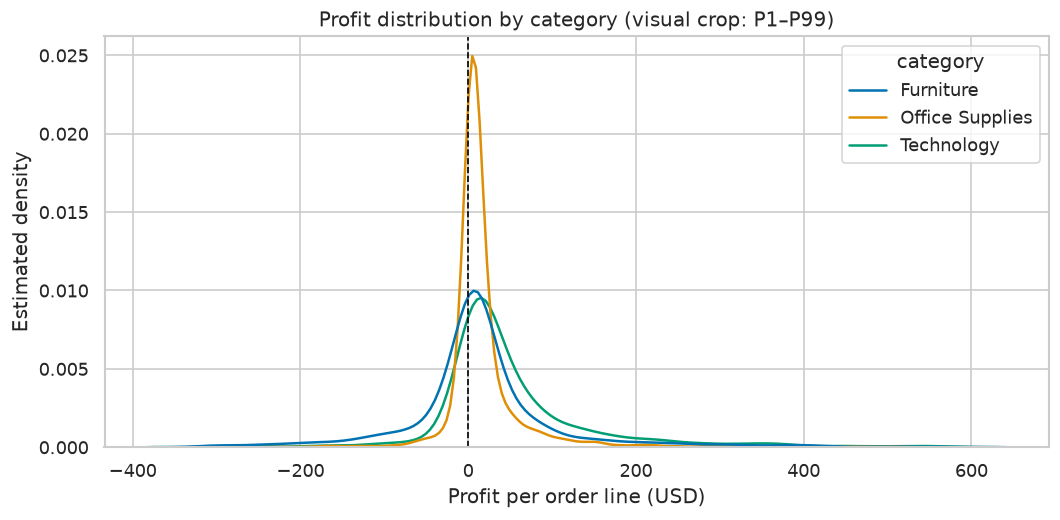

In [5]:
lo,hi=df.profit.quantile([.01,.99])
fig,ax=plt.subplots(figsize=(9,4.5))
sns.kdeplot(data=df[df.profit.between(lo,hi)],x="profit",hue="category",ax=ax,common_norm=False)
ax.axvline(0,linestyle="--",color="black",linewidth=1)
ax.set(xlabel="Profit per order line (USD)",ylabel="Estimated density",title="Profit distribution by category (visual crop: P1–P99)")
fig.tight_layout();fig.savefig(FIG_DIR/"02_profit_kde.png");fig.savefig(FIG_DIR/"02_profit_kde.svg");plt.show()

### 6. Box plots and uncertainty (95% confidence intervals)
The left panel describes profit variation by discount group. The right panel gives bootstrapped **mean profit per line** with 95% confidence intervals, resampling **orders**, not individual lines, so multiple lines belonging to the same order are kept together. This is sampling uncertainty within a demonstration dataset, not a population sampling guarantee.

**Important:** The visual boxplot range is cropped, not the underlying data. No correlation shown should be interpreted as causation.

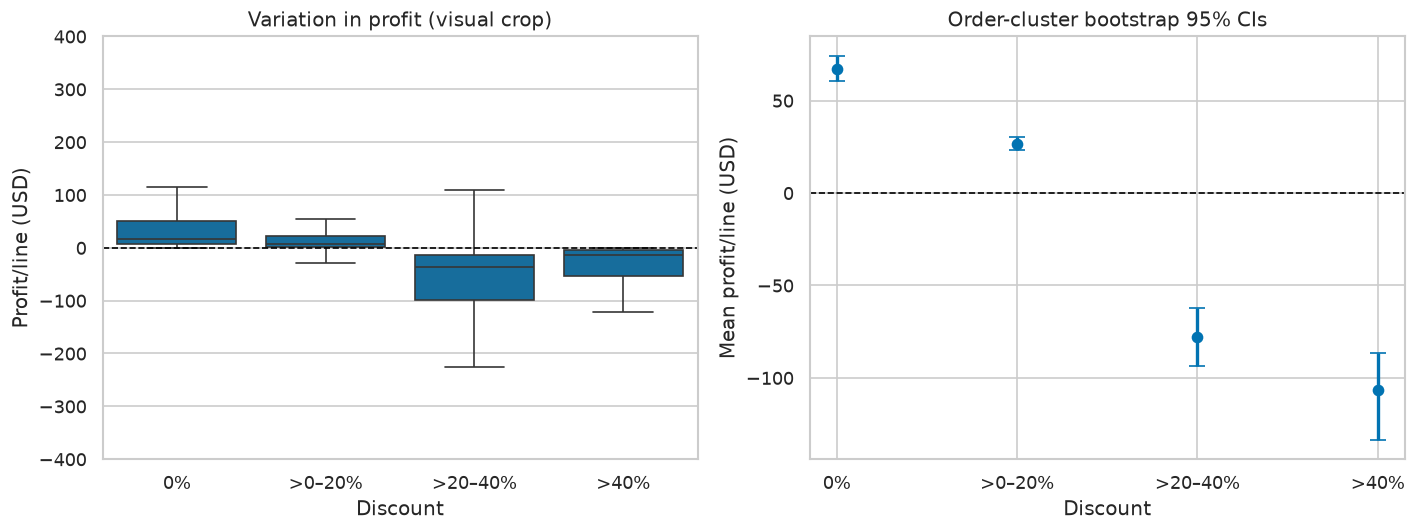

,discount_band,mean,ci_low,ci_high
0,0%,66.90,60.33,74.32
1,>0–20%,26.50,23.00,30.43
2,>20–40%,-77.86,-93.59,-62.11
3,>40%,-106.71,-133.60,-86.64


In [6]:
rng=np.random.default_rng(42)
labels=["0%",">0–20%",">20–40%",">40%"]
ci=[]
for label in labels:
    part=df.loc[df.discount_band.astype(str)==label]
    order_stats=part.groupby("order_id").agg(total=("profit","sum"),n=("profit","size"))
    sums=order_stats.total.to_numpy();counts=order_stats.n.to_numpy()
    indices=rng.integers(0,len(sums),size=(600,len(sums)))
    boot_mean=sums[indices].sum(axis=1)/counts[indices].sum(axis=1)
    ci.append({"discount_band":label,"mean":part.profit.mean(),
               "ci_low":np.quantile(boot_mean,.025),"ci_high":np.quantile(boot_mean,.975)})
ci_df=pd.DataFrame(ci)
ci_df.to_csv(TABLE_DIR/"bootstrap_mean_profit_ci95.csv",index=False)

fig,ax=plt.subplots(1,2,figsize=(12,4.6))
sns.boxplot(data=df,x="discount_band",y="profit",showfliers=False,order=labels,ax=ax[0])
ax[0].set_ylim(-400,400)
ax[0].axhline(0,color="black",linewidth=1,linestyle="--")
ax[0].set(xlabel="Discount",ylabel="Profit/line (USD)",title="Variation in profit (visual crop)")
points=np.arange(len(labels))
ax[1].errorbar(points,ci_df["mean"],
 yerr=[ci_df["mean"]-ci_df["ci_low"],ci_df["ci_high"]-ci_df["mean"]],
 fmt="o",capsize=5,linewidth=2)
ax[1].axhline(0,color="black",linewidth=1,linestyle="--")
ax[1].set_xticks(points,labels)
ax[1].set(xlabel="Discount",ylabel="Mean profit/line (USD)",title="Order-cluster bootstrap 95% CIs")
fig.tight_layout();fig.savefig(FIG_DIR/"03_boxplot_and_ci.png");fig.savefig(FIG_DIR/"03_boxplot_and_ci.svg");plt.show()
display(ci_df.round(2))

### 7. X–Y relationships: correlation heatmap
Pearson correlation measures linear association, **not causality**. `year` and customer/product IDs are excluded because they are not comparable numeric measures. Since line profit margins can be extreme for small sales, their correlation may be unstable.

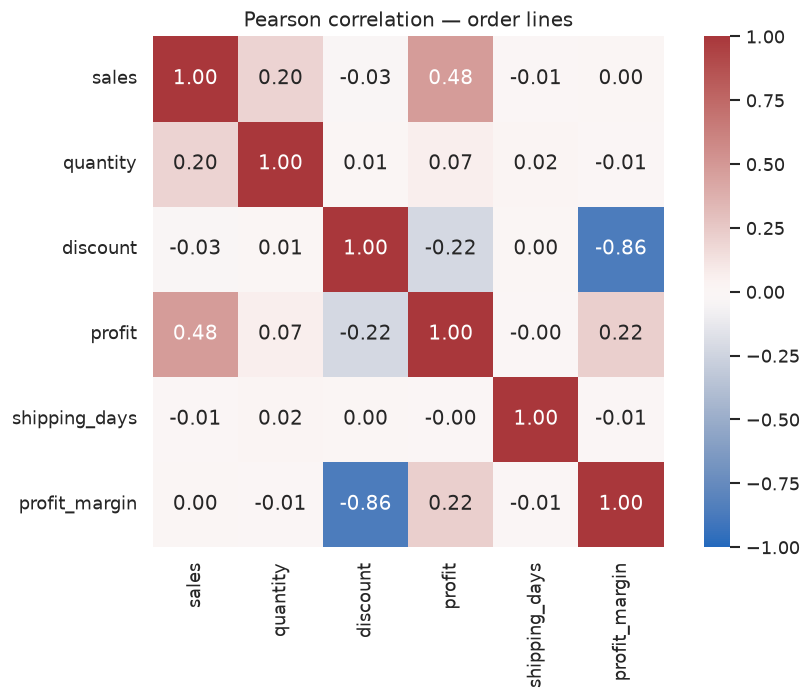

In [7]:
numerics=df[["sales","quantity","discount","profit","shipping_days","profit_margin"]]
corr=numerics.corr(method="pearson")
fig,ax=plt.subplots(figsize=(8,6))
sns.heatmap(corr,annot=True,fmt=".2f",center=0,cmap="vlag",vmin=-1,vmax=1,square=True,ax=ax)
ax.set_title("Pearson correlation — order lines")
fig.tight_layout();fig.savefig(FIG_DIR/"04_correlation_heatmap.png");fig.savefig(FIG_DIR/"04_correlation_heatmap.svg");plt.show()

### 8. Interactive scatter/bubble chart (Plotly)
Each dot is an order line. Bubble size represents sales. We reproducibly sample 2,500 lines **for browser responsiveness**, and never use the sample for KPIs. The HTML is interactive and can be opened in a web browser.

In [8]:
display_df=df.sample(min(len(df),2500),random_state=42).copy()
fig=px.scatter(display_df,x="discount",y="profit",size="sales",color="category",
 hover_data=["state","sub_category","order_id","sales"],
 title="Discount vs. profit (2,500 line-item sample)",
 labels={"discount":"Discount rate","profit":"Profit per line (USD)","category":"Category"},
 size_max=26,opacity=.65)
fig.update_layout(template="plotly_white")
fig.write_html(FIG_DIR/"05_discount_profit_bubbles.html",include_plotlyjs=True)
fig.show()

### 9. Temporal change, quantities and geography
These charts use appropriate axes and never truncate bar baselines. State names map to US abbreviations only for the map visualization; state names in the raw data are not modified.

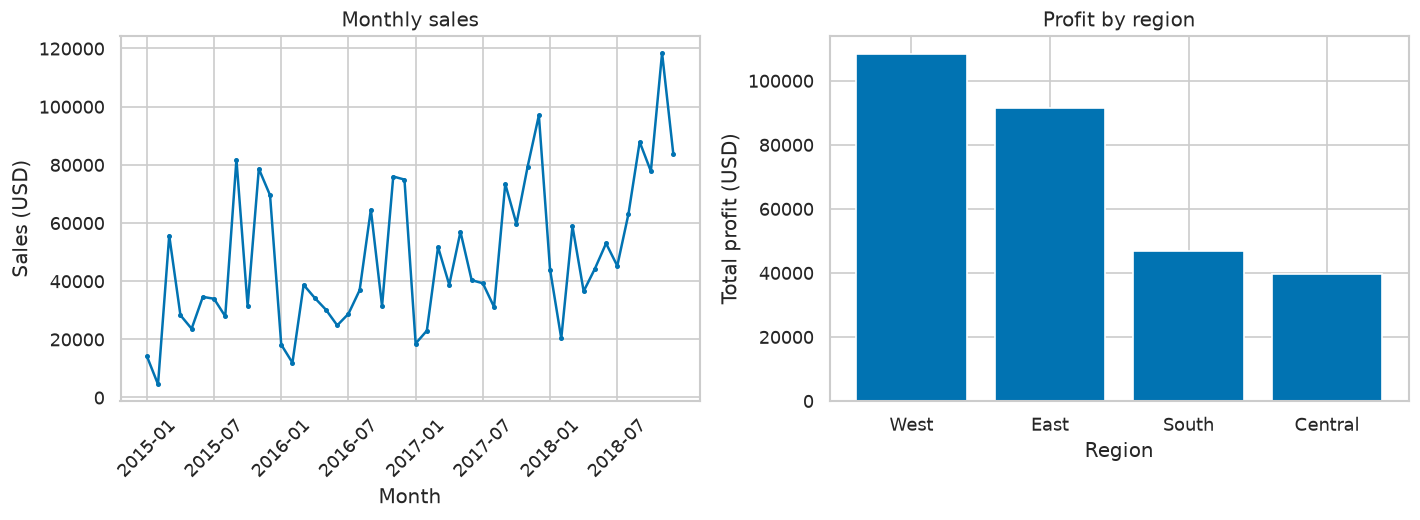

In [9]:
fig,ax=plt.subplots(1,2,figsize=(12,4.5))
ax[0].plot(by_month.month,pd.to_numeric(by_month.sales),marker="o",markersize=2)
ax[0].set(title="Monthly sales",ylabel="Sales (USD)",xlabel="Month")
ax[0].set_xticks(range(0,len(by_month),6),by_month.month.iloc[::6],rotation=45)
regions=by_region.sort_values("profit",ascending=False)
ax[1].bar(regions.region,regions.profit)
ax[1].set_ylim(bottom=0)
ax[1].set(title="Profit by region",ylabel="Total profit (USD)",xlabel="Region")
fig.tight_layout();fig.savefig(FIG_DIR/"06_trend_and_region.png");fig.savefig(FIG_DIR/"06_trend_and_region.svg");plt.show()

state_codes={
'Alabama':'AL','Alaska':'AK','Arizona':'AZ','Arkansas':'AR','California':'CA','Colorado':'CO',
'Connecticut':'CT','Delaware':'DE','District of Columbia':'DC','Florida':'FL','Georgia':'GA',
'Hawaii':'HI','Idaho':'ID','Illinois':'IL','Indiana':'IN','Iowa':'IA','Kansas':'KS','Kentucky':'KY',
'Louisiana':'LA','Maine':'ME','Maryland':'MD','Massachusetts':'MA','Michigan':'MI','Minnesota':'MN',
'Mississippi':'MS','Missouri':'MO','Montana':'MT','Nebraska':'NE','Nevada':'NV','New Hampshire':'NH',
'New Jersey':'NJ','New Mexico':'NM','New York':'NY','North Carolina':'NC','North Dakota':'ND',
'Ohio':'OH','Oklahoma':'OK','Oregon':'OR','Pennsylvania':'PA','Rhode Island':'RI',
'South Carolina':'SC','South Dakota':'SD','Tennessee':'TN','Texas':'TX','Utah':'UT',
'Vermont':'VT','Virginia':'VA','Washington':'WA','West Virginia':'WV','Wisconsin':'WI','Wyoming':'WY'}
map_df=by_state.assign(state_code=lambda d:d.state.map(state_codes))
fig=px.choropleth(map_df,locations="state_code",locationmode="USA-states",color="profit",
 scope="usa",hover_name="state",hover_data={"sales":":,.0f","profit":":,.0f"},
 color_continuous_scale="RdBu",color_continuous_midpoint=0,
 title="Profit by US state (USD; diverging scale)")
fig.update_layout(template="plotly_white")
fig.write_html(FIG_DIR/"07_state_profit_map.html",include_plotlyjs=True)
fig.show()

### 10. Findings, limitations and actionable decisions
**Verified aggregate patterns for this mirror (2015–2018):**
- Overall sales ~$2.30M, profit ~$286K, weighted margin ~12.47%.
- Furniture margins are low (~2.49%) despite ~$742K in sales.
- Deep discounts (over 20%) are associated with negative aggregate profit. **This association is not causal proof.**
- Texas, Ohio, Pennsylvania, and Illinois have negative aggregate profit.

**Proposed actions:** pilot a manager-approval process for discounts over 20%, review Furniture/Tables pricing and supplier terms, and audit loss-making states. Track margin and conversion after changes; an A/B test is required to estimate causal effects.

**Limits:** a simulated/educational historical dataset, not a random population sample; no inventory costs, advertising budgets, or customer acquisition costs; no proof that price changes would improve profitability. Source may differ by mirror or version.

**Reproducibility:** The notebook exports CSV tables, PNG/SVG vectors and interactive HTML files into `outputs/`. Dashboard implementation is under `dashboard/app.py`.